# 🎬🛒 Review Sentiment Analysis – Extended Project (multi-class, imbalance-aware, deployable)

This notebook extends the original IMDB binary-sentiment project into a more complete NLP study.

| # | Extension | Where |
|---|-----------|-------|
| 1 | Product/venue-review dataset with **5-star** labels (`Yelp/yelp_review_full`) | §1–2 |
| 2 | **Neutral class** (1–2★ negative, 3★ neutral, 4–5★ positive) | §1 |
| 3 | **Class-imbalance** experiment: baseline vs class weights vs over-/under-sampling | §5 |
| 4 | **GridSearchCV** over TF-IDF + model hyper-parameters (leak-free, via `Pipeline`) | §4 |
| 5 | **BiGRU + GloVe** embeddings | §6 |
| 6 | **RoBERTa-base** fine-tuning with a class-weighted loss | §7 |
| 7 | Proper **evaluation**: macro-F1, per-class F1, ordinal error for 5★, confident-error analysis | §4, §8–9 |
| 8 | **Explainability** with LIME | §9 |
| 9 | **Cross-domain test**: train on restaurants → test on movies and Amazon products | §10 |
| 10 | **Gradio app** + deployment notes | §11 |

**Methodology fixes over the first version**
- Model selection uses **cross-validation / a validation split**, never the test set. The test set is scored once per final model.
- Preprocessing is **ablated** (raw vs cleaned text) instead of assumed to help.
- The headline metric is **macro-F1** (accuracy hides weak minority classes such as *Neutral*).

> **Runtime:** use a GPU (*Runtime → Change runtime type → T4 GPU*). Set `QUICK_RUN = True` in §0 for a ~10-minute smoke test.

## 0. Setup

In [1]:
!pip install -q datasets transformers evaluate accelerate wordcloud gensim lime gradio

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
import re, time, copy, random, warnings
from collections import Counter
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from datasets import load_dataset, Dataset

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import ComplementNB
from sklearn.svm import LinearSVC
from sklearn.utils import resample
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, f1_score, classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, mean_absolute_error,
                             precision_recall_fscore_support)

warnings.filterwarnings("ignore")
nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

SEED = 42
def seed_everything(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
seed_everything()
sns.set_style("whitegrid")
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [4]:
# ---- Experiment configuration -------------------------------------------------
QUICK_RUN = False            # True -> tiny subsets, finishes in minutes (for debugging)

N_TRAIN  = 4_000  if QUICK_RUN else 50_000    # Yelp reviews drawn from the 650k train split
N_TEST   = 2_000  if QUICK_RUN else 10_000    # Yelp reviews drawn from the 50k test split
N_TRANSFORMER_TRAIN = 2_000 if QUICK_RUN else 20_000   # RoBERTa uses a subset to fit a free T4
N_XDOMAIN = 1_000 if QUICK_RUN else 3_000     # reviews per external domain (cross-domain test)
GRU_EPOCHS = 2    if QUICK_RUN else 5
CV_FOLDS   = 2    if QUICK_RUN else 3

LABELS3 = ["Negative", "Neutral", "Positive"]

## 1. Data: Yelp 5-star reviews → 3 sentiment classes

`Yelp/yelp_review_full` has 650k train / 50k test reviews with star ratings 1–5. We draw a random subset, then:

- **5-class task:** the star rating itself (ordinal).
- **3-class task (primary):** 1–2★ → *Negative*, **3★ → *Neutral***, 4–5★ → *Positive*.

The test set is **held out** and touched only when a final model is scored. A 10 % validation split of the training subset is used for model/epoch selection.

In [5]:
raw = load_dataset("Yelp/yelp_review_full")

def to_df(split, n):
    df = raw[split].shuffle(seed=SEED).select(range(n)).to_pandas()
    df["text"] = df["text"].str.replace(r"\\n", " ", regex=True).str.strip()   # Yelp stores "\n" literally
    df["stars"] = df["label"] + 1                                               # 1..5
    df["sent3"] = df["label"].map({0: 0, 1: 0, 2: 1, 3: 2, 4: 2})               # 0=Neg, 1=Neu, 2=Pos
    return df

full_train = to_df("train", N_TRAIN)
test_df    = to_df("test",  N_TEST)
train_df, val_df = train_test_split(full_train, test_size=0.10, stratify=full_train["stars"], random_state=SEED)
train_df, val_df = train_df.reset_index(drop=True), val_df.reset_index(drop=True)
print(f"train={len(train_df):,}  val={len(val_df):,}  test={len(test_df):,}")
train_df.head()

README.md:   0%|          | 0.00/6.72k [00:00<?, ?B/s]

yelp_review_full/train-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  299MB            

yelp_review_full/train-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

yelp_review_full/test-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 23.5MB            

yelp_review_full/test-00000-of-00001.par(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/650000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/50000 [00:00<?, ? examples/s]

train=45,000  val=5,000  test=10,000


,label,text,stars,sent3
0,4,Love the food especially lamb kabob and chapli...,5,2
1,3,The Smith Center consists of a number of theat...,4,2
2,0,"Wow, the chicken was too burned and they charg...",1,0
3,4,So you want breakfast do you? This contemporar...,5,2
4,4,I am so in love with this place and would come...,5,2


## 2. Exploratory Data Analysis

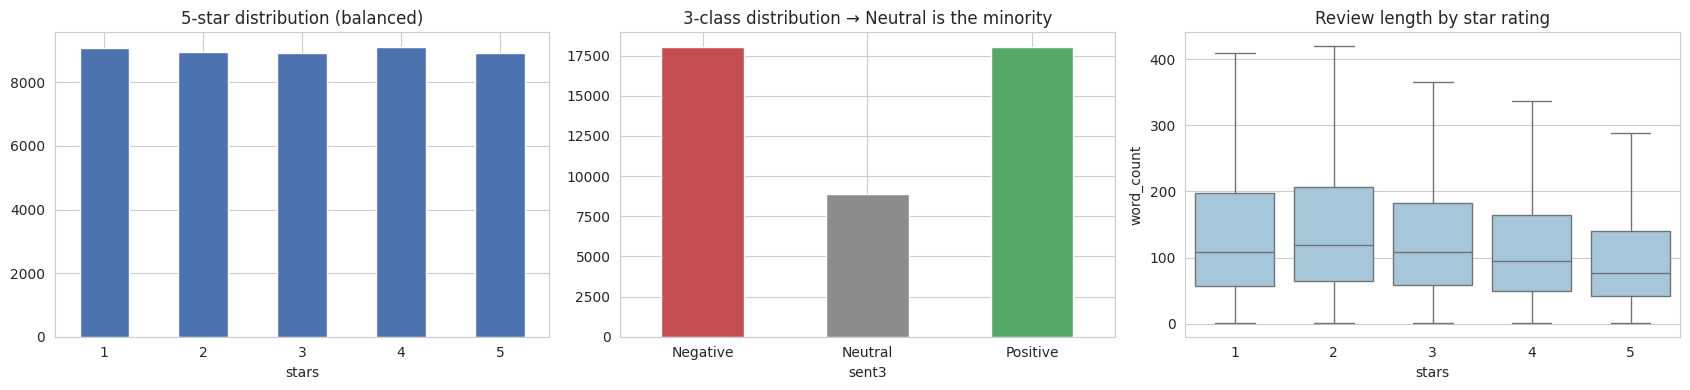

        mean    50%     max
stars                      
1      151.6  108.0  1026.0
2      154.9  119.0   980.0
3      138.3  108.0   946.0
4      124.0   95.0  1034.0
5      107.6   76.0   954.0


In [6]:
train_df["word_count"] = train_df["text"].str.split().str.len()

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
train_df["stars"].value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("5-star distribution (balanced)"); ax[0].tick_params(axis="x", rotation=0)

counts3 = train_df["sent3"].map(dict(enumerate(LABELS3))).value_counts()[LABELS3]
counts3.plot.bar(ax=ax[1], color=["#C44E52", "#8C8C8C", "#55A868"])
ax[1].set_title("3-class distribution → Neutral is the minority"); ax[1].tick_params(axis="x", rotation=0)

sns.boxplot(data=train_df, x="stars", y="word_count", ax=ax[2], showfliers=False, color="#9ecae1")
ax[2].set_title("Review length by star rating")
plt.tight_layout(); plt.show()

print(train_df.groupby("stars")["word_count"].describe()[["mean", "50%", "max"]].round(1))

In [7]:
# Why Neutral is hard: 3-star reviews mix praise and complaints
for t in train_df[train_df.stars == 3]["text"].sample(3, random_state=SEED):
    print("•", t[:350], "...\n")

• GHETTO!  I had the chili con queso and it was VELVEETA with salsa.  I even asked about it!  I was really disappointed with it.  It distracted me so much, I didn't even order dinner.  I went to the one at the Biltmore. ...

• Not a bad hotel and the room was very nice with a good view. On checking in we did receive some vouchers however our booking stated that we would get $50 of various bits and pieces which we did not receive.  However there was not any tea or coffee making facilities within the room and I am a huge tea drinker and my partner a coffee drinker. The air ...

• This park seems a bit confusing to me. I know construction is over but it always appears to have something being worked on or redone and just seems unfinished to me.  I enjoyed the lake a lot since there's few places of water around town. The large adjacent jogging trail through the desert seems a bit dangerous and unkempt to me. Definitely not som ...



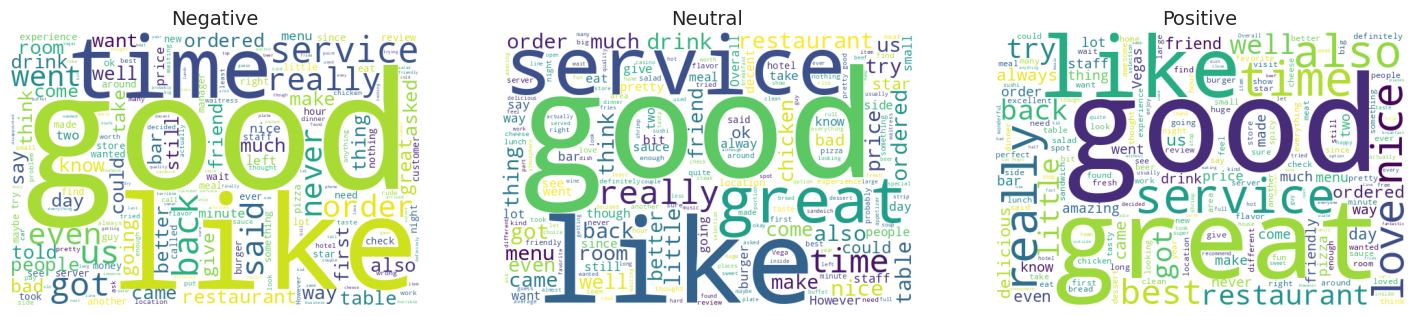

In [8]:
from wordcloud import WordCloud
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sw = set(stopwords.words("english")) | {"place", "food", "go", "get", "one", "u", "would"}
for ax, (lbl, name) in zip(axes, enumerate(LABELS3)):
    grp = train_df[train_df.sent3 == lbl]["text"]
    txt = " ".join(grp.sample(min(1500, len(grp)), random_state=SEED))
    ax.imshow(WordCloud(width=600, height=400, background_color="white", stopwords=sw).generate(txt))
    ax.axis("off"); ax.set_title(name, fontsize=14)
plt.show()

## 3. Text Preprocessing – and does it actually help?

The original pipeline lower-cases, strips HTML/URLs/punctuation, removes stop-words (keeping negations) and lemmatizes.
That is a *hypothesis*, not a fact: for sentiment, removing words like "very" or "but" can discard signal, and transformers want raw text.
So we **ablate**: train the same model on raw vs cleaned text and let the validation score decide what the classical models receive.

In [9]:
KEEP = {"not", "no", "nor", "never", "very", "too", "but", "only", "more", "most"}   # sentiment-bearing "stop-words"
stop_words = set(stopwords.words("english")) - KEEP
lemmatize = lru_cache(maxsize=None)(WordNetLemmatizer().lemmatize)

def clean_text(text):
    text = text.lower()
    text = re.sub(r"<.*?>", " ", text)               # HTML tags
    text = re.sub(r"http\S+|www\S+", " ", text)      # URLs
    text = re.sub(r"n't\b", " not", text)            # don't -> do not
    text = re.sub(r"[^a-z\s]", " ", text)            # punctuation, digits
    return " ".join(lemmatize(w) for w in text.split() if w not in stop_words and len(w) > 1)

print(clean_text("I didn't like this place! <br />The service was BAD :( http://yelp.com"))

not like place service bad


In [10]:
%%time
for df in (train_df, val_df, test_df):
    df["clean"] = df["text"].apply(clean_text)

CPU times: user 6.63 s, sys: 856 µs, total: 6.63 s
Wall time: 11.1 s


In [11]:
def ablation_score(col):
    pipe = Pipeline([
        ("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_features=100_000)),
        ("clf",   LogisticRegression(max_iter=1000, C=2, class_weight="balanced")),
    ])
    pipe.fit(train_df[col], train_df["sent3"])
    return f1_score(val_df["sent3"], pipe.predict(val_df[col]), average="macro")

ablation = pd.Series({"raw text": ablation_score("text"), "cleaned text": ablation_score("clean")},
                     name="validation macro-F1")
display(ablation.to_frame().style.format("{:.4f}"))

TEXT_COL = "text" if ablation["raw text"] >= ablation["cleaned text"] else "clean"
prep = (lambda t: t) if TEXT_COL == "text" else clean_text        # same transform at inference time
print(f"→ classical models will use: {TEXT_COL!r}")

,validation macro-F1
raw text,0.7198
cleaned text,0.7267


→ classical models will use: 'clean'


## 4. Classical Models with `GridSearchCV`

Each model lives in a `Pipeline(TfidfVectorizer → classifier)`, so the vectorizer is **re-fit inside every CV fold** (no vocabulary leakage from validation folds).
We tune TF-IDF settings and model regularisation together, scoring on **macro-F1**. Class weights are `balanced` where supported; `ComplementNB` is the imbalance-friendly Naive Bayes variant.

Add more values to the grids for a deeper search (cost grows multiplicatively).

In [13]:
# ---- Evaluation helpers + shared leaderboard ----------------------------------
leaderboard = []

def log_result(name, y_true, y_pred, fit_seconds=np.nan):
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=[0, 1, 2], zero_division=0)
    leaderboard.append({"Model": name,
                        "Accuracy": accuracy_score(y_true, y_pred),
                        "Macro-F1": f1.mean(),
                        "Neutral F1": f1[1],
                        "Neutral recall": rec[1],
                        "Fit time (s)": fit_seconds})

def show_confusion(y_true, y_pred, title, labels=LABELS3, cmap="Blues"):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, display_labels=labels,
                                            normalize="true", cmap=cmap, values_format=".2f")
    plt.title(title); plt.show()

In [14]:
search_space = {
    "Logistic Regression": (LogisticRegression(max_iter=1000, class_weight="balanced"),
                            {"clf__C": [1, 4, 16]}),
    "Linear SVM":          (LinearSVC(class_weight="balanced"),
                            {"clf__C": [0.05, 0.2, 1.0]}),
    "Complement NB":       (ComplementNB(),
                            {"clf__alpha": [0.1, 0.5, 1.0]}),
}
tfidf_grid = {"tfidf__ngram_range": [(1, 1), (1, 2)]}
cv = StratifiedKFold(CV_FOLDS, shuffle=True, random_state=SEED)

searches, cv_rows = {}, []
for name, (est, grid) in search_space.items():
    pipe = Pipeline([("tfidf", TfidfVectorizer(sublinear_tf=True, min_df=3, max_features=100_000)),
                     ("clf", est)])
    gs = GridSearchCV(pipe, {**tfidf_grid, **grid}, scoring="f1_macro", cv=cv, n_jobs=-1)
    t0 = time.time(); gs.fit(train_df[TEXT_COL], train_df["sent3"]); secs = time.time() - t0
    searches[name] = gs
    cv_rows.append({"Model": name, "Best CV macro-F1": gs.best_score_, "Best params": gs.best_params_,
                    "Search time (s)": round(secs)})
    print(f"{name:20s} CV macro-F1 = {gs.best_score_:.4f}   {gs.best_params_}")

pd.DataFrame(cv_rows).sort_values("Best CV macro-F1", ascending=False).reset_index(drop=True)

Logistic Regression  CV macro-F1 = 0.7308   {'clf__C': 1, 'tfidf__ngram_range': (1, 2)}
Linear SVM           CV macro-F1 = 0.7232   {'clf__C': 0.2, 'tfidf__ngram_range': (1, 2)}
Complement NB        CV macro-F1 = 0.6521   {'clf__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}


,Model,Best CV macro-F1,Best params,Search time (s)
0,Logistic Regression,0.730831,"{'clf__C': 1, 'tfidf__ngram_range': (1, 2)}",221
1,Linear SVM,0.723158,"{'clf__C': 0.2, 'tfidf__ngram_range': (1, 2)}",113
2,Complement NB,0.652112,"{'clf__alpha': 0.1, 'tfidf__ngram_range': (1, 2)}",96


Best classical model (by CV): Logistic Regression 

              precision    recall  f1-score   support

    Negative      0.850     0.823     0.836      4024
     Neutral      0.505     0.581     0.541      1983
    Positive      0.852     0.816     0.834      3993

    accuracy                          0.772     10000
   macro avg      0.736     0.740     0.737     10000
weighted avg      0.783     0.772     0.777     10000



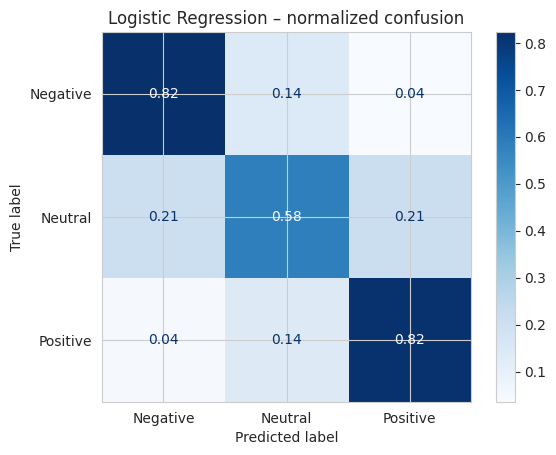

In [15]:
# Final (one-shot) test evaluation of each tuned model. Selection was done by CV, not on the test set.
test_in = test_df[TEXT_COL]
classical_preds = {}
for name, gs in searches.items():
    classical_preds[name] = gs.best_estimator_.predict(test_in)
    log_result(f"TF-IDF + {name} (tuned)", test_df["sent3"], classical_preds[name])

best_classical = max(searches, key=lambda n: searches[n].best_score_)     # chosen by CV score
print("Best classical model (by CV):", best_classical, "\n")
print(classification_report(test_df["sent3"], classical_preds[best_classical], target_names=LABELS3, digits=3))
show_confusion(test_df["sent3"], classical_preds[best_classical], f"{best_classical} – normalized confusion")

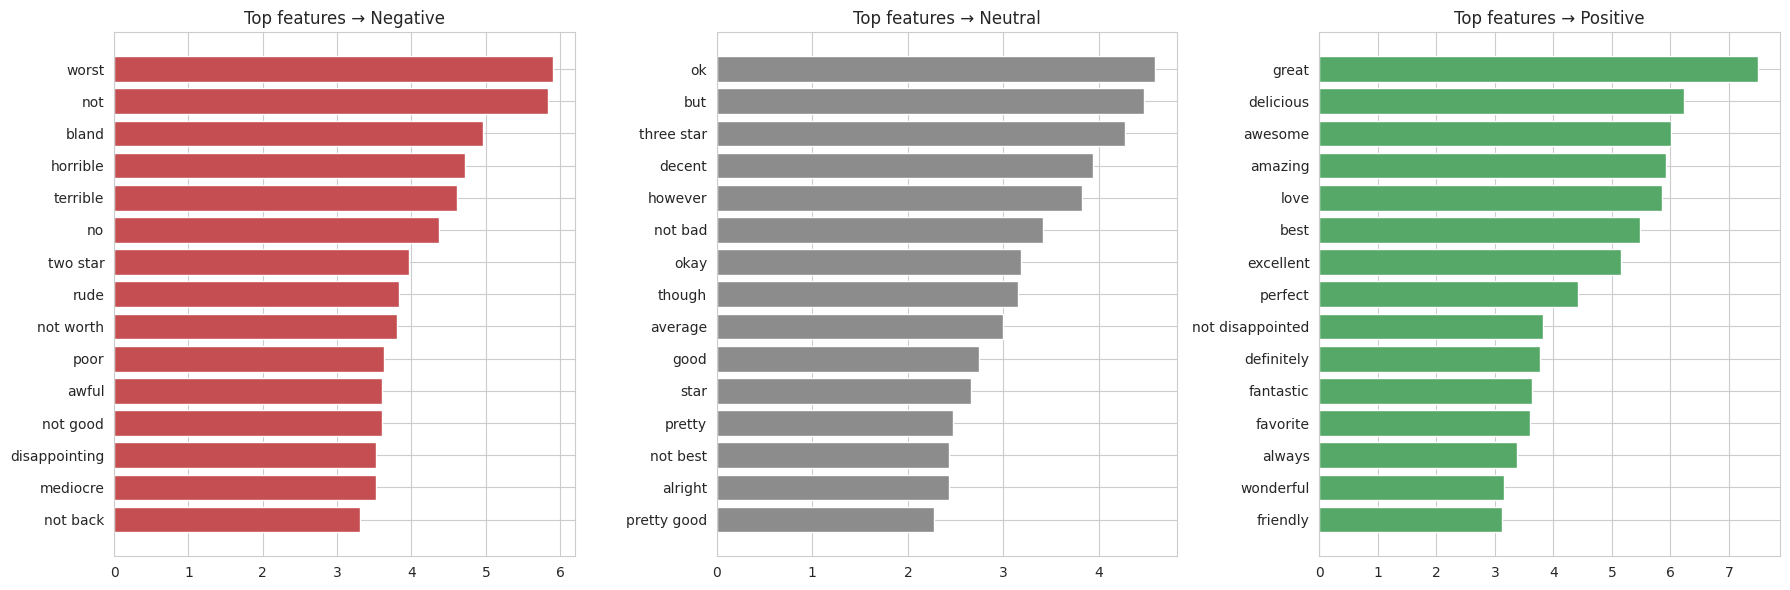

In [16]:
# Which words drive the (Logistic Regression) predictions, per class?
lr_pipe = searches["Logistic Regression"].best_estimator_
feats = np.array(lr_pipe.named_steps["tfidf"].get_feature_names_out())
coef = lr_pipe.named_steps["clf"].coef_                      # shape (3, n_features)

fig, axes = plt.subplots(1, 3, figsize=(18, 6))
for ax, k, name, col in zip(axes, range(3), LABELS3, ["#C44E52", "#8C8C8C", "#55A868"]):
    idx = np.argsort(coef[k])[-15:]
    ax.barh(feats[idx], coef[k][idx], color=col); ax.set_title(f"Top features → {name}")
plt.tight_layout(); plt.show()

5-class  accuracy=0.583  macro-F1=0.580  MAE=0.520 stars  within±1★=0.929


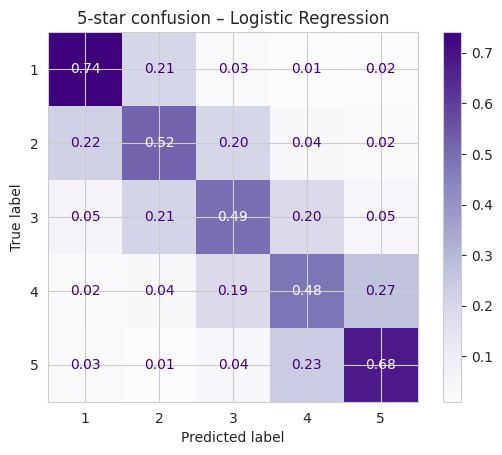

In [17]:
# Same pipeline on the full 5-star task (ordinal labels): accuracy, macro-F1, MAE and "within one star"
pipe5 = clone(searches[best_classical].best_estimator_).fit(train_df[TEXT_COL], train_df["stars"])
p5 = pipe5.predict(test_in)
y5 = test_df["stars"].values
print(f"5-class  accuracy={accuracy_score(y5, p5):.3f}  macro-F1={f1_score(y5, p5, average='macro'):.3f}  "
      f"MAE={mean_absolute_error(y5, p5):.3f} stars  within±1★={(np.abs(y5 - p5) <= 1).mean():.3f}")
ConfusionMatrixDisplay.from_predictions(y5, p5, normalize="true", cmap="Purples", values_format=".2f")
plt.title(f"5-star confusion – {best_classical}"); plt.show()

## 5. Handling Class Imbalance (controlled experiment)

Yelp is star-balanced, so after merging, Neutral is 20 % of the data. Real review streams are usually much more skewed, so we **simulate that**: keep all Positive, 50 % of Negative and only **10 % of Neutral** in the training set, and compare strategies on the same untouched test set.

| Strategy | Idea |
|----------|------|
| None | Train as-is (baseline) |
| Class weights | Penalise mistakes on rare classes more |
| Random over-sampling | Duplicate minority-class rows up to the majority size |
| Random under-sampling | Drop majority-class rows down to the minority size |

Accuracy can look fine while the minority class collapses – watch **Neutral recall / F1** and **macro-F1**.

In [18]:
keep_frac = {0: 0.5, 1: 0.1, 2: 1.0}
imb = pd.concat([g.sample(frac=keep_frac[k], random_state=SEED) for k, g in train_df.groupby("sent3")]).reset_index(drop=True)
print("Simulated imbalanced train distribution:\n", imb["sent3"].map(dict(enumerate(LABELS3))).value_counts().to_string(), "\n")

def oversample(df):
    m = df["sent3"].value_counts().max()
    return pd.concat([resample(g, replace=True, n_samples=m, random_state=SEED) for _, g in df.groupby("sent3")])

def undersample(df):
    m = df["sent3"].value_counts().min()
    return pd.concat([g.sample(m, random_state=SEED) for _, g in df.groupby("sent3")])

def fit_and_score(df, class_weight=None):
    pipe = Pipeline([("tfidf", TfidfVectorizer(ngram_range=(1, 2), min_df=3, sublinear_tf=True, max_features=100_000)),
                     ("clf", LogisticRegression(max_iter=1000, C=2, class_weight=class_weight))])
    pipe.fit(df[TEXT_COL], df["sent3"])
    p = pipe.predict(test_df[TEXT_COL])
    _, rec, f1, _ = precision_recall_fscore_support(test_df["sent3"], p, labels=[0, 1, 2], zero_division=0)
    return {"Accuracy": accuracy_score(test_df["sent3"], p), "Macro-F1": f1.mean(),
            "Neutral recall": rec[1], "Neutral F1": f1[1]}

imb_results = pd.DataFrame({
    "No handling":          fit_and_score(imb),
    "Class weights":        fit_and_score(imb, class_weight="balanced"),
    "Random over-sampling": fit_and_score(oversample(imb)),
    "Random under-sampling": fit_and_score(undersample(imb)),
    "(Reference) balanced full data": fit_and_score(train_df),
}).T
display(imb_results.style.format("{:.3f}").background_gradient(cmap="Greens", subset=["Macro-F1", "Neutral F1"]))

Simulated imbalanced train distribution:
 sent3
Positive    18038
Negative     9026
Neutral       891 



,Accuracy,Macro-F1,Neutral recall,Neutral F1
No handling,0.738,0.547,0.002,0.003
Class weights,0.757,0.629,0.138,0.226
Random over-sampling,0.748,0.593,0.071,0.125
Random under-sampling,0.704,0.677,0.585,0.484
(Reference) balanced full data,0.778,0.712,0.377,0.451


## 6. Deep Learning I – BiGRU with pre-trained GloVe embeddings

A bidirectional GRU reads the review in both directions; we feed it **GloVe (100-d, Wikipedia + Gigaword)** vectors so words like *"awful"* and *"terrible"* start out close together. The sequence is summarised by **max-pool + mean-pool** over time, then a linear layer. Training uses a **class-weighted loss** and keeps the **best epoch by validation macro-F1**.

Tokenisation follows GloVe's convention (`don't` → `do` `n't`, `it's` → `it` `'s`) so more words are found in the embedding table.

In [19]:
import gensim.downloader as gensim_api

TOKEN_RE = re.compile(r"n't|'[a-z]+|[a-z]+|[!?]")
def simple_tokens(text):
    text = re.sub(r"n't\b", " n't", text.lower().replace("<br />", " "))
    return TOKEN_RE.findall(text)

MAX_LEN, VOCAB_SIZE = 256, 30_000
word_counts = Counter(w for t in train_df["text"] for w in simple_tokens(t))
itos = ["<pad>", "<unk>"] + [w for w, _ in word_counts.most_common(VOCAB_SIZE)]
stoi = {w: i for i, w in enumerate(itos)}

def encode(text):
    ids = [stoi.get(w, 1) for w in simple_tokens(text)][:MAX_LEN]
    return ids + [0] * (MAX_LEN - len(ids))

glove = gensim_api.load("glove-wiki-gigaword-100")           # ~130 MB download, cached afterwards
rng = np.random.RandomState(SEED)
emb_matrix = rng.normal(0, 0.3, (len(itos), glove.vector_size)).astype("float32")
emb_matrix[0] = 0.0
hits = 0
for w, i in stoi.items():
    if w in glove:
        emb_matrix[i] = glove[w]; hits += 1
print(f"GloVe covers {hits / len(stoi):.1%} of the {len(stoi):,}-word vocabulary")

[==================================================] 100.0% 128.1/128.1MB downloaded
GloVe covers 89.5% of the 30,002-word vocabulary


In [20]:
class BiGRUClassifier(nn.Module):
    def __init__(self, emb_matrix, n_classes=3, hidden=128, dropout=0.4):
        super().__init__()
        self.emb  = nn.Embedding.from_pretrained(torch.tensor(emb_matrix), freeze=False, padding_idx=0)
        self.gru  = nn.GRU(emb_matrix.shape[1], hidden, batch_first=True, bidirectional=True)
        self.drop = nn.Dropout(dropout)
        self.fc   = nn.Linear(hidden * 4, n_classes)          # [max-pool ; mean-pool] x 2 directions

    def forward(self, x, lengths):
        e = self.drop(self.emb(x))
        packed = nn.utils.rnn.pack_padded_sequence(e, lengths.cpu(), batch_first=True, enforce_sorted=False)
        out, _ = self.gru(packed)
        out, _ = nn.utils.rnn.pad_packed_sequence(out, batch_first=True, total_length=x.size(1))
        mask = (x != 0).unsqueeze(-1)
        max_pool  = out.masked_fill(~mask, -1e9).max(dim=1).values
        mean_pool = (out * mask).sum(dim=1) / mask.sum(dim=1).clamp(min=1)
        return self.fc(self.drop(torch.cat([max_pool, mean_pool], dim=1)))

def make_loader(df, shuffle):
    ids = torch.tensor([encode(t) for t in df["text"]])
    return DataLoader(TensorDataset(ids, torch.tensor(df["sent3"].values)), batch_size=128, shuffle=shuffle)

train_loader, val_loader, test_loader = make_loader(train_df, True), make_loader(val_df, False), make_loader(test_df, False)

def run_epoch(model, loader, loss_fn, optimizer=None):
    training = optimizer is not None
    model.train(training)
    preds, ys, total = [], [], 0.0
    with torch.set_grad_enabled(training):
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            logits = model(xb, (xb != 0).sum(1).clamp(min=1))
            loss = loss_fn(logits, yb)
            if training:
                optimizer.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 1.0); optimizer.step()
            total += loss.item() * len(yb)
            preds.append(logits.argmax(1).cpu()); ys.append(yb.cpu())
    y, p = torch.cat(ys).numpy(), torch.cat(preds).numpy()
    return total / len(y), f1_score(y, p, average="macro"), p

epoch 1: train loss 54156.132 F1 0.627 | val loss 0.639 F1 0.701
epoch 2: train loss 60042.782 F1 0.728 | val loss 0.587 F1 0.727
epoch 3: train loss 20099.333 F1 0.766 | val loss 0.595 F1 0.721
epoch 4: train loss 65488.094 F1 0.804 | val loss 0.686 F1 0.716
epoch 5: train loss 10911.927 F1 0.838 | val loss 0.702 F1 0.718


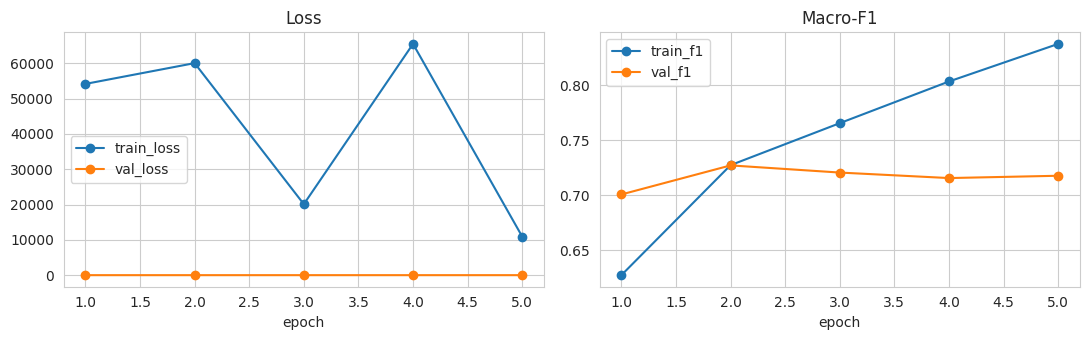

              precision    recall  f1-score   support

    Negative      0.863     0.802     0.831      4024
     Neutral      0.487     0.564     0.523      1983
    Positive      0.845     0.838     0.841      3993

    accuracy                          0.769     10000
   macro avg      0.732     0.735     0.732     10000
weighted avg      0.781     0.769     0.774     10000



In [21]:
seed_everything()
gru = BiGRUClassifier(emb_matrix).to(device)
class_w = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=train_df["sent3"])
loss_fn = nn.CrossEntropyLoss(weight=torch.tensor(class_w, dtype=torch.float32, device=device))
optimizer = torch.optim.AdamW(gru.parameters(), lr=2e-3, weight_decay=1e-2)

history, best_f1, best_state = [], -1, None
t0 = time.time()
for epoch in range(1, GRU_EPOCHS + 1):
    tr_loss, tr_f1, _ = run_epoch(gru, train_loader, loss_fn, optimizer)
    va_loss, va_f1, _ = run_epoch(gru, val_loader, loss_fn)
    history.append({"epoch": epoch, "train_loss": tr_loss, "val_loss": va_loss, "train_f1": tr_f1, "val_f1": va_f1})
    print(f"epoch {epoch}: train loss {tr_loss:.3f} F1 {tr_f1:.3f} | val loss {va_loss:.3f} F1 {va_f1:.3f}")
    if va_f1 > best_f1:
        best_f1, best_state = va_f1, copy.deepcopy(gru.state_dict())
gru_seconds = time.time() - t0

gru.load_state_dict(best_state)
_, _, gru_pred = run_epoch(gru, test_loader, loss_fn)
log_result("BiGRU + GloVe", test_df["sent3"], gru_pred, gru_seconds)

hist = pd.DataFrame(history).set_index("epoch")
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
hist[["train_loss", "val_loss"]].plot(ax=ax[0], marker="o", title="Loss")
hist[["train_f1", "val_f1"]].plot(ax=ax[1], marker="o", title="Macro-F1")
plt.tight_layout(); plt.show()
print(classification_report(test_df["sent3"], gru_pred, target_names=LABELS3, digits=3))

## 7. Deep Learning II – Fine-tune `roberta-base`

RoBERTa is a stronger encoder than DistilBERT (more data, longer pre-training, no next-sentence objective) but ~2× slower. To use the **class-imbalance handling** from §5 inside the Transformer, we subclass `Trainer` and apply a **class-weighted cross-entropy loss**.

Evaluation during training uses the **validation** split; the **test** split is scored once at the end.
Try `distilbert-base-uncased` (as in the first project) by changing `MODEL_NAME`, or `xlm-roberta-base` for multilingual reviews.

In [22]:
from scipy.special import softmax
from transformers import (AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments,
                          Trainer, DataCollatorWithPadding, pipeline, set_seed)

MODEL_NAME = "roberta-base"
ID2LABEL = {0: "NEGATIVE", 1: "NEUTRAL", 2: "POSITIVE"}
LABEL2ID = {v: k for k, v in ID2LABEL.items()}
set_seed(SEED)

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def to_hf(df):
    ds = Dataset.from_pandas(df[["text", "sent3"]].rename(columns={"sent3": "labels"}), preserve_index=False)
    return ds.map(lambda b: tokenizer(b["text"], truncation=True, max_length=256), batched=True, remove_columns=["text"])

tf_train = train_df.sample(min(N_TRANSFORMER_TRAIN, len(train_df)), random_state=SEED)
tf_val   = val_df.sample(min(2_000, len(val_df)), random_state=SEED)
ds_train, ds_val, ds_test = to_hf(tf_train), to_hf(tf_val), to_hf(test_df)
print(f"RoBERTa data → train {len(ds_train):,} | val {len(ds_val):,} | test {len(ds_test):,}")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Map:   0%|          | 0/20000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/10000 [00:00<?, ? examples/s]

RoBERTa data → train 20,000 | val 2,000 | test 10,000


In [24]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    p = np.argmax(logits, axis=-1)
    return {"accuracy": accuracy_score(labels, p), "macro_f1": f1_score(labels, p, average="macro")}

class WeightedTrainer(Trainer):
    """Trainer with class-weighted cross-entropy to counter label imbalance."""
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels = inputs.pop("labels")
        outputs = model(**inputs)
        loss = nn.functional.cross_entropy(outputs.logits, labels,
                                           weight=self.class_weights.to(outputs.logits.device))
        return (loss, outputs) if return_outputs else loss

model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=3, id2label=ID2LABEL, label2id=LABEL2ID)

# Calculate warmup steps based on epochs and batch size
batch_size = 16
num_epochs = 2
total_steps = (len(ds_train) // batch_size) * num_epochs
warmup_steps = int(0.1 * total_steps)

args = TrainingArguments(
    output_dir="roberta-reviews", num_train_epochs=num_epochs,
    per_device_train_batch_size=batch_size, per_device_eval_batch_size=64,
    learning_rate=2e-5, weight_decay=0.01, warmup_steps=warmup_steps, lr_scheduler_type="linear",
    eval_strategy="epoch", save_strategy="no", logging_steps=100,
    fp16=torch.cuda.is_available(), report_to="none", seed=SEED,
)
tf_class_w = torch.tensor(compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=tf_train["sent3"]),
                          dtype=torch.float32)
trainer = WeightedTrainer(model=model, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                          data_collator=DataCollatorWithPadding(tokenizer),
                          compute_metrics=compute_metrics, class_weights=tf_class_w)
t0 = time.time(); trainer.train(); roberta_seconds = time.time() - t0
print(f"Training took {roberta_seconds / 60:.1f} min")

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.560294,0.551927,0.804500,0.769564
2,0.388247,0.590200,0.805000,0.770635


Training took 8.9 min


              precision    recall  f1-score   support

    Negative      0.900     0.856     0.877      4024
     Neutral      0.571     0.659     0.612      1983
    Positive      0.899     0.876     0.887      3993

    accuracy                          0.825     10000
   macro avg      0.790     0.797     0.792     10000
weighted avg      0.834     0.825     0.829     10000



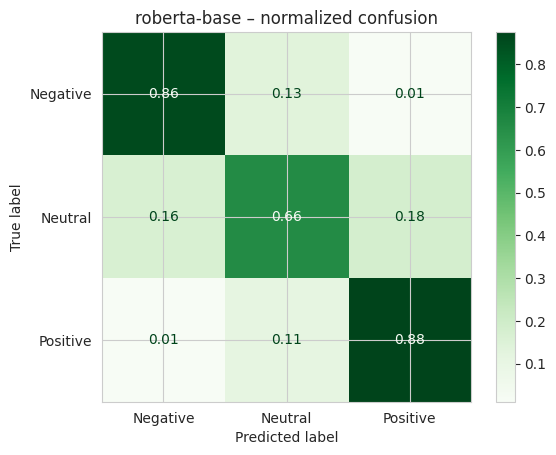

In [25]:
out = trainer.predict(ds_test)
roberta_probs = softmax(out.predictions, axis=-1)
roberta_pred  = roberta_probs.argmax(1)
log_result(f"{MODEL_NAME} (fine-tuned, {len(ds_train):,} reviews)", test_df["sent3"], roberta_pred, roberta_seconds)

print(classification_report(test_df["sent3"], roberta_pred, target_names=LABELS3, digits=3))
show_confusion(test_df["sent3"], roberta_pred, f"{MODEL_NAME} – normalized confusion", cmap="Greens")

## 8. Model Comparison

All models are scored on the **same held-out test set**. Look at *Neutral F1* – it is where models differ most.

,Model,Accuracy,Macro-F1,Neutral F1,Neutral recall,Fit time (s)
0,"roberta-base (fine-tuned, 20,000 reviews)",0.825,0.792,0.612,0.659,532
1,TF-IDF + Logistic Regression (tuned),0.772,0.737,0.541,0.581,nan
2,BiGRU + GloVe,0.769,0.732,0.523,0.564,146
3,TF-IDF + Linear SVM (tuned),0.776,0.722,0.484,0.441,nan
4,TF-IDF + Complement NB (tuned),0.742,0.645,0.309,0.221,nan


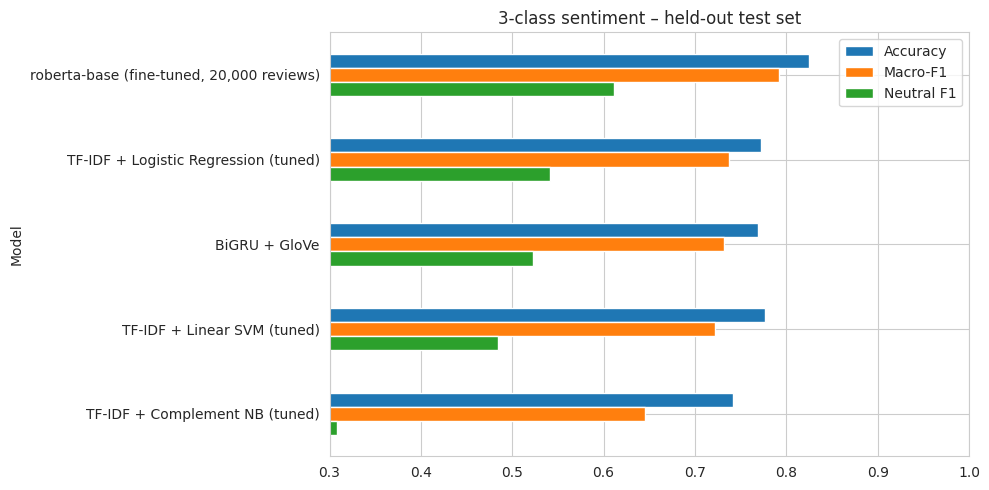

In [26]:
board = pd.DataFrame(leaderboard).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(board.style.format({"Accuracy": "{:.3f}", "Macro-F1": "{:.3f}", "Neutral F1": "{:.3f}",
                            "Neutral recall": "{:.3f}", "Fit time (s)": "{:.0f}"}).background_gradient(
        cmap="Greens", subset=["Macro-F1", "Neutral F1"]))

ax = board.set_index("Model")[["Accuracy", "Macro-F1", "Neutral F1"]].plot.barh(figsize=(10, 5))
ax.invert_yaxis(); ax.set_xlim(0.3, 1.0); ax.set_title("3-class sentiment – held-out test set")
plt.tight_layout(); plt.show()

## 9. Error Analysis & Explainability

**Confident mistakes** are the most informative failures: the model was sure and wrong, which often reveals label noise, sarcasm or genuinely mixed reviews.
**LIME** perturbs the text and shows which words pushed a prediction towards each class.

In [27]:
err = test_df.assign(true=test_df["sent3"].map(dict(enumerate(LABELS3))),
                     pred=[LABELS3[i] for i in roberta_pred],
                     conf=roberta_probs.max(1))
confident_errors = err[err["true"] != err["pred"]].sort_values("conf", ascending=False).head(6)
for _, r in confident_errors.iterrows():
    print(f"TRUE {r['true']:8s} | PRED {r['pred']:8s} ({r['conf']:.0%}) | {r['stars']}★")
    print("  ", r["text"][:300], "...\n")

TRUE Neutral  | PRED Positive (100%) | 3★
   I love this place. Everytime I come to Scottsdale, I have to visit, a couple of times too  No matter what I try, I'm never disappointed, never!  Last night I had the chimichanga (sp?) and it was delicious!  I felt it could have been shared but it made for a great lunch today. ...

TRUE Neutral  | PRED Positive (100%) | 3★
   I am a Mediterranean food junkie!! Khoury's is really authentic Lebanese food which always satisfies my cravings. It is extremely delicious and addicting! I recommend the chicken kabob plate with hummus. The fatosh salad is amazing too! I've had problems in the past with slow service but they are ve ...

TRUE Neutral  | PRED Positive (100%) | 3★
   Love this place since it was tea planet. ...

TRUE Negative | PRED Positive (100%) | 2★
   The buffalo blue cheeseburger is delicious.  Smells good had to stop Can't get enough of that blue cheese buffalo burger smells and Tastes so good you got to try it. ...

TRUE Neutral  |

TF-IDF + Logistic Regression: Neutral (53%)


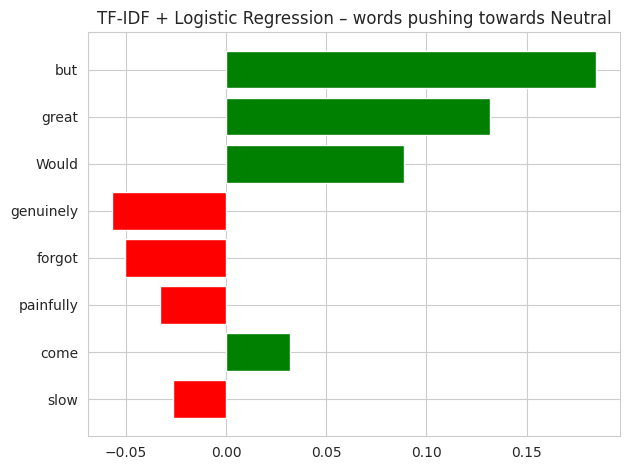

RoBERTa: Neutral (81%)


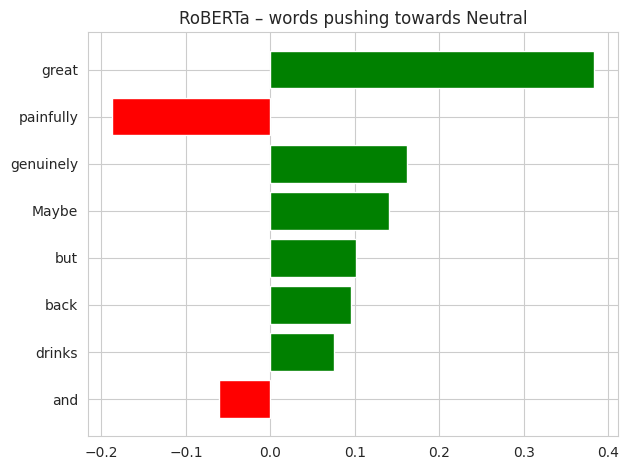

In [28]:
from lime.lime_text import LimeTextExplainer

clf_pipe = pipeline("text-classification", model=trainer.model, tokenizer=tokenizer, top_k=None,
                    device=0 if torch.cuda.is_available() else -1)

def roberta_proba(texts):
    """List[str] -> (n, 3) probabilities ordered [Negative, Neutral, Positive]."""
    out = clf_pipe(list(texts), truncation=True, max_length=256, batch_size=32)
    return np.array([[d["score"] for d in sorted(row, key=lambda d: LABEL2ID[d["label"]])] for row in out])

def lr_proba(texts):
    return lr_pipe.predict_proba([prep(t) for t in texts])

explainer = LimeTextExplainer(class_names=LABELS3, random_state=SEED)
sample = ("The food was genuinely great but the service was painfully slow and they forgot our drinks. "
          "Would I come back? Maybe.")

for name, fn, n in [("TF-IDF + Logistic Regression", lr_proba, 1000), ("RoBERTa", roberta_proba, 300)]:
    probs = fn([sample])[0]
    top = int(probs.argmax())
    print(f"{name}: {LABELS3[top]} ({probs[top]:.0%})")
    exp = explainer.explain_instance(sample, fn, num_features=8, labels=[top], num_samples=n)
    exp.as_pyplot_figure(label=top); plt.title(f"{name} – words pushing towards {LABELS3[top]}")
    plt.tight_layout(); plt.show()

## 10. Does it generalise? Cross-domain evaluation

Models trained on **restaurant** reviews are tested – without any retraining – on **movie** reviews (IMDB) and **product** reviews (Amazon). Those datasets are *binary*, so we compare only the Negative vs Positive probabilities (Neutral is ignored). A large drop from the in-domain score signals **domain shift**: sentiment words are not universal (*"unpredictable"* is praise for a thriller and a complaint about a toaster).

Reviews longer than 256 tokens are truncated for RoBERTa, which slightly handicaps it on long IMDB reviews.

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

amazon_polarity/test-00000-of-00001.parq(…): reconstructing file:   0%|          |  0.00B /  117MB            

amazon_polarity/test-00000-of-00001.parq(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3600000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/400000 [00:00<?, ? examples/s]

,TF-IDF + LR,RoBERTa
Yelp (in-domain),0.929,0.964
IMDB (movies),0.820,0.902
Amazon (products),0.868,0.953


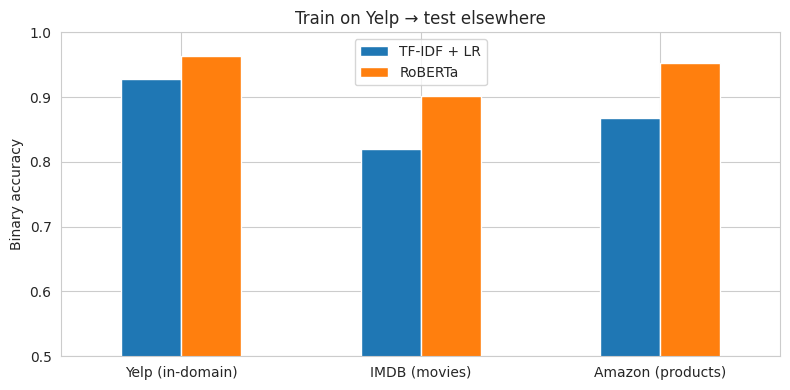

In [29]:
imdb = load_dataset("stanfordnlp/imdb", split="test").shuffle(seed=SEED).select(range(N_XDOMAIN))
amz  = load_dataset("fancyzhx/amazon_polarity", split="test").shuffle(seed=SEED).select(range(N_XDOMAIN))

yelp_bin = test_df[test_df["sent3"] != 1].head(N_XDOMAIN)
domains = {
    "Yelp (in-domain)":      (yelp_bin["text"].tolist(), (yelp_bin["sent3"] == 2).astype(int).values),
    "IMDB (movies)":         (imdb["text"], np.array(imdb["label"])),
    "Amazon (products)":     ([f"{t}. {c}" for t, c in zip(amz["title"], amz["content"])], np.array(amz["label"])),
}

def binary_accuracy(proba_fn, texts, y):
    P = proba_fn(list(texts))
    return accuracy_score(y, (P[:, 2] > P[:, 0]).astype(int))

xd = pd.DataFrame({
    model_name: {dom: binary_accuracy(fn, texts, y) for dom, (texts, y) in domains.items()}
    for model_name, fn in [("TF-IDF + LR", lr_proba), ("RoBERTa", roberta_proba)]
})
display(xd.style.format("{:.3f}").background_gradient(cmap="Greens", axis=None))
ax = xd.plot.bar(rot=0, figsize=(8, 4), ylim=(0.5, 1.0)); ax.set_ylabel("Binary accuracy")
ax.set_title("Train on Yelp → test elsewhere"); plt.tight_layout(); plt.show()

## 11. Save the Model & Deploy with Gradio

The fine-tuned model is saved with its tokenizer and label mapping. The next cell writes `app.py` (also provided as a separate file) – a Gradio app with a **single-review** tab (class probabilities) and a **batch CSV** tab.

**Free hosting on Hugging Face Spaces:** create a Space (SDK = *Gradio*), upload `app.py`, `requirements.txt` and the `sentiment_model/` folder (or `trainer.model.push_to_hub("your-name/review-sentiment")` and set `MODEL_DIR` to that id).

In [30]:
trainer.save_model("sentiment_model")
tokenizer.save_pretrained("sentiment_model")

# Optional – persist to Google Drive:
# from google.colab import drive; drive.mount('/content/drive')
# !cp -r sentiment_model /content/drive/MyDrive/

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('sentiment_model/tokenizer_config.json', 'sentiment_model/tokenizer.json')

In [31]:
%%writefile app.py
"""Gradio demo for the 3-class (Negative / Neutral / Positive) review sentiment model.

Run locally:      python app.py
Custom model:     MODEL_DIR=path/or/hub-id python app.py
"""
import os

import gradio as gr
import pandas as pd
import torch
from transformers import pipeline

MODEL_DIR = os.environ.get("MODEL_DIR", "sentiment_model")
MAX_LEN = 256
MAX_BATCH_ROWS = 500

clf = pipeline(
    "text-classification",
    model=MODEL_DIR,
    tokenizer=MODEL_DIR,
    top_k=None,  # return the score of every class, not just the top one
    device=0 if torch.cuda.is_available() else -1,
)

EXAMPLES = [
    "An absolute masterpiece! The acting was superb and the story kept me hooked.",
    "I wasted two hours of my life. Terrible script and wooden acting.",
    "Not bad, but not great either. Some parts were slow.",
    "I didn't hate it, honestly. It was surprisingly good!",
    "This product stopped working after two days. Do not buy.",
    "Decent value for the price. Battery life is average, camera is okay.",
]


def _scores(texts):
    """Return one {label: probability} dict per input text."""
    out = clf(texts, truncation=True, max_length=MAX_LEN, batch_size=16)
    return [{d["label"].title(): float(d["score"]) for d in row} for row in out]


def predict_one(text):
    if not text or not text.strip():
        return {}
    return _scores([text])[0]


def predict_csv(file):
    """Batch mode: CSV with a 'review' column (falls back to the first column)."""
    if file is None:
        return pd.DataFrame()
    path = file if isinstance(file, str) else file.name
    df = pd.read_csv(path).head(MAX_BATCH_ROWS)
    col = "review" if "review" in df.columns else df.columns[0]
    scores = _scores(df[col].fillna("").astype(str).tolist())
    df["sentiment"] = [max(s, key=s.get) for s in scores]
    df["confidence"] = [round(max(s.values()), 3) for s in scores]
    return df


with gr.Blocks(title="Review Sentiment Analyzer") as demo:
    gr.Markdown(
        "# Review Sentiment Analyzer\n"
        "Fine-tuned RoBERTa that classifies a review as **Negative**, **Neutral** or **Positive**. "
        "Trained on Yelp reviews (1-2 stars = negative, 3 = neutral, 4-5 = positive); "
        "it transfers reasonably to other review domains but is not guaranteed to."
    )
    with gr.Tab("Single review"):
        inp = gr.Textbox(lines=5, label="Review", placeholder="Paste or type a review here...")
        btn = gr.Button("Analyze", variant="primary")
        out = gr.Label(num_top_classes=3, label="Sentiment")
        gr.Examples(examples=[[e] for e in EXAMPLES], inputs=inp)
        btn.click(predict_one, inputs=inp, outputs=out)
    with gr.Tab("Batch (CSV)"):
        gr.Markdown(f"Upload a CSV with a `review` column (first {MAX_BATCH_ROWS} rows are scored).")
        f = gr.File(label="CSV file", file_types=[".csv"])
        run = gr.Button("Run on file", variant="primary")
        table = gr.Dataframe(label="Predictions")
        run.click(predict_csv, inputs=f, outputs=table)

if __name__ == "__main__":
    demo.launch()

Writing app.py


In [32]:
import importlib, app
importlib.reload(app)
app.demo.launch(share=True)        # prints a public *.gradio.live link valid for ~72 h

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8d0cd013c4e17e0870.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 12. Summary & Discussion

In [33]:
print("Final leaderboard (3-class, held-out test set):\n")
print(board.round(3).to_string(index=False))
print("\nCross-domain binary accuracy:\n")
print(xd.round(3).to_string())

Final leaderboard (3-class, held-out test set):

                                    Model  Accuracy  Macro-F1  Neutral F1  Neutral recall  Fit time (s)
roberta-base (fine-tuned, 20,000 reviews)     0.824     0.792       0.612           0.659       532.044
     TF-IDF + Logistic Regression (tuned)     0.772     0.737       0.541           0.581           NaN
                            BiGRU + GloVe     0.769     0.732       0.523           0.564       146.007
              TF-IDF + Linear SVM (tuned)     0.776     0.722       0.484           0.441           NaN
           TF-IDF + Complement NB (tuned)     0.742     0.645       0.309           0.221           NaN

Cross-domain binary accuracy:

                   TF-IDF + LR  RoBERTa
Yelp (in-domain)         0.929    0.964
IMDB (movies)            0.820    0.902
Amazon (products)        0.868    0.953


**How to read the results** *(fill in your own numbers and observations after running)*

- **Neutral is the hard class.** Check *Neutral F1* against the other two classes: 3★ reviews contain both praise and complaints, so even humans disagree. Expect all models to lose most of their score here.
- **Imbalance (§5):** compare *No handling* with the other rows – the gap in *Neutral recall* shows what accuracy was hiding. Class weights are usually the cheapest option; over-sampling duplicates rows and can overfit, under-sampling throws data away.
- **Classical vs deep:** TF-IDF models train in seconds and are interpretable; RoBERTa should gain most on negation, mixed sentiment and sarcasm, at a much higher compute cost. Note that the BiGRU/TF-IDF models saw all training rows while RoBERTa saw a subset – raise `N_TRANSFORMER_TRAIN` for a fairer comparison.
- **Domain shift (§10):** the drop from in-domain to IMDB/Amazon quantifies how much a model leans on domain-specific vocabulary.
- **Limitations:** single random seed, one dataset family, English only, subsets of the full corpus. For stronger claims, repeat with several seeds and report mean ± std.

**Further ideas**
- Treat the 5-star task as **ordinal regression** (or use an ordinal loss) rather than flat classification.
- **Aspect-based sentiment** ("food: positive, service: negative") instead of one label per review.
- **Calibration** (temperature scaling) and an "uncertain → human review" threshold for borderline Neutral predictions.
- **Distil** RoBERTa into a smaller model, or quantise it, for cheaper serving.
- Multilingual / code-mixed reviews with `xlm-roberta-base`.
- Track experiments with Weights & Biases or MLflow; add unit tests for `clean_text`.